# Task 3 — Country-Wise Netflix Content Analysis

Analyze country associations, rank countries by title count, and compare content types geographically.

**Project:** Auspify Technologies — Data Analysis Using Python Internship  
**Dataset:** Netflix catalogue CSV supplied for this internship  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Import Libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 1. Load The Cleaned Dataset

In [2]:
df = pd.read_csv("netflix_cleaned.csv")
print("Loaded cleaned dataset:", df.shape)
display(df.head())

Loaded cleaned dataset: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 2. Split multi-country records
One title may be associated with more than one country. `explode()` creates one row per title-country association. Unknown countries are excluded from rankings.

In [3]:
country_df = df[["show_id", "title", "country", "type"]].copy()
country_df = country_df[
    country_df["country"].notna() & country_df["country"].ne("Unknown")
]
country_df["country"] = country_df["country"].str.split(",")
country_df = country_df.explode("country")
country_df["country"] = country_df["country"].str.strip()
display(country_df.head(10))

,show_id,title,country,type
0,s1,Dick Johnson Is Dead,United States,Movie
1,s3,Ganglands,France,Tv Show
2,s6,Midnight Mass,United States,Tv Show
3,s14,Confessions of an Invisible Girl,Brazil,Movie
4,s8,Sankofa,United States,Movie
5,s9,The Great British Baking Show,United Kingdom,Tv Show
6,s10,The Starling,United States,Movie
7,s939,Motu Patlu in the Game of Zones,India,Movie
8,s13,Je Suis Karl,Germany,Movie
9,s940,Motu Patlu in Wonderland,India,Movie


## 3. Count titles by country
Count distinct IDs for each country so a title is counted once per country.

In [4]:
country_counts = (
    country_df.groupby("country")["show_id"]
    .nunique().sort_values(ascending=False)
)
top_countries = country_counts.head(10)
print("Top 10 Countries:")
display(top_countries.to_frame("title_count"))
top_countries.to_csv("task3_top_countries.csv", header=["title_count"])

Top 10 Countries:


,title_count
country,
United States,3240
India,1057
United Kingdom,638
Pakistan,421
Canada,271
Japan,259
South Korea,214
France,213
Spain,182


## 4. Chart: Top 10 countries

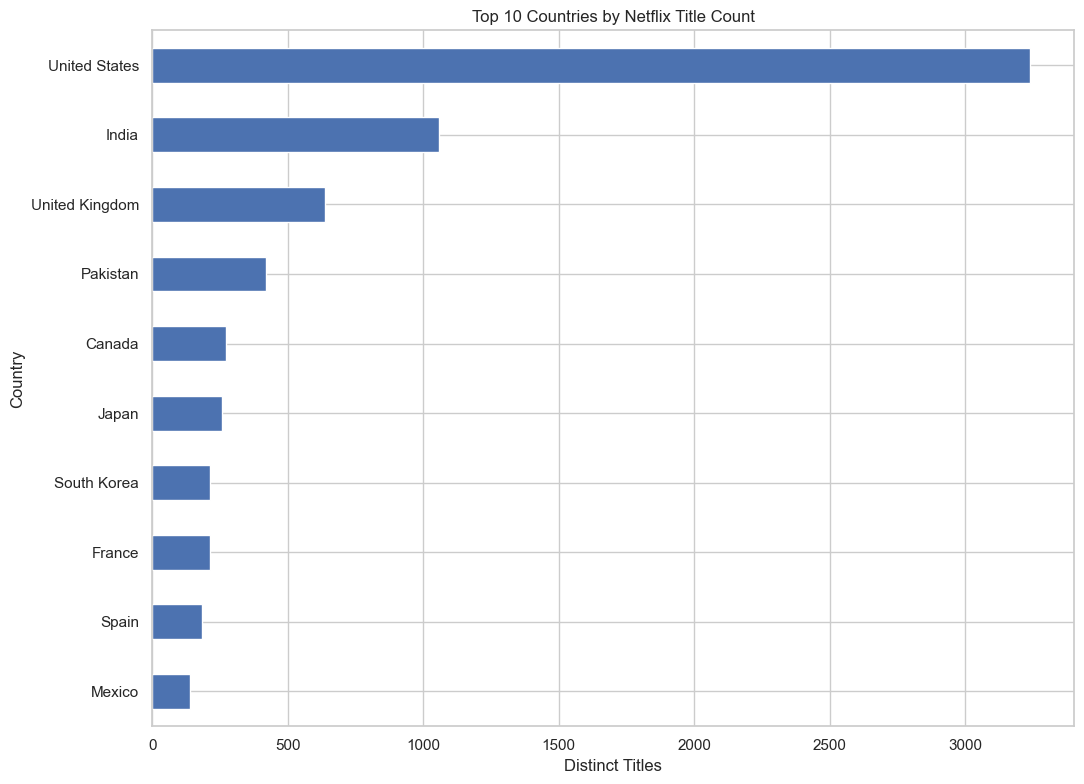

In [5]:
fig, ax = plt.subplots(figsize=(11, 8))
top_countries.sort_values().plot(kind="barh", ax=ax)
ax.set(title="Top 10 Countries by Netflix Title Count",
       xlabel="Distinct Titles", ylabel="Country")
plt.tight_layout()
plt.savefig("task3_top_countries.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Compare Movies and TV Shows by country

type,Movie,Tv Show
country,,
Canada,187,84
France,148,65
India,976,81
Japan,87,172
Mexico,90,48
Pakistan,71,350
South Korea,49,165
Spain,129,53
United Kingdom,387,251


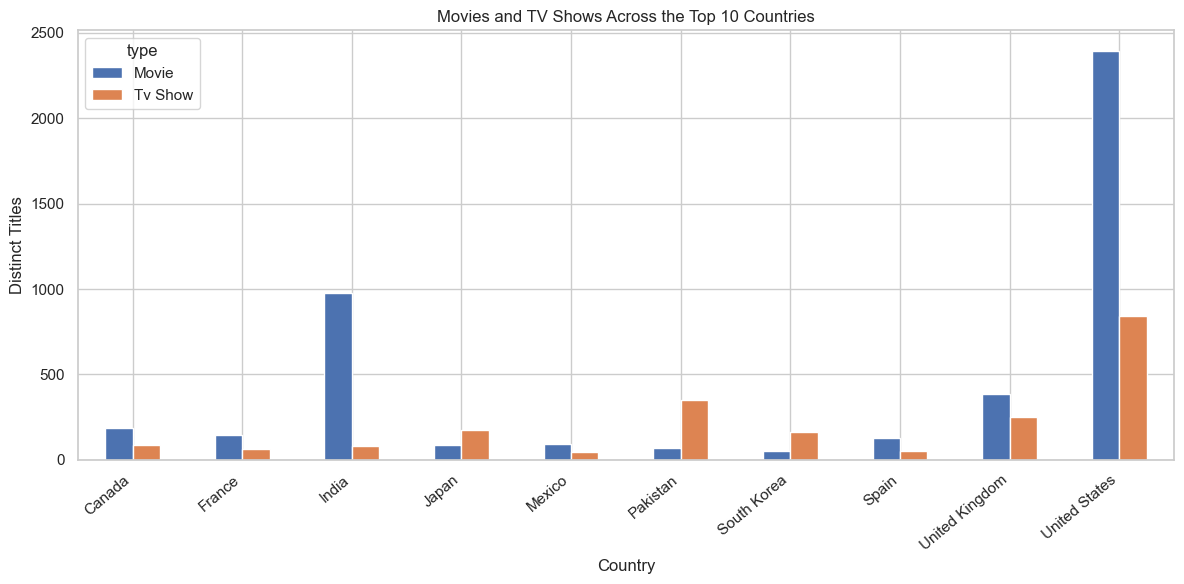

In [6]:
top_names = top_countries.index
top_country_rows = country_df[country_df["country"].isin(top_names)]
country_type = (
    top_country_rows.groupby(["country", "type"])["show_id"]
    .nunique().unstack(fill_value=0)
)
display(country_type)

ax = country_type.plot(kind="bar", figsize=(12, 6))
ax.set(title="Movies and TV Shows Across the Top 10 Countries",
       xlabel="Country", ylabel="Distinct Titles")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("task3_country_by_type.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Findings
Report the highest-ranked countries and any differences between Movies and TV Shows.